# Generative tagging with Qwen3 — Part B · Training

Qwen3-1.7B (instruction model), fine-tuned with Axolotl (QLoRA) to answer with the tag in a chat.

**Public Weights & Biases project:** [https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags](https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags)

**Adapter repository:** `rajatsxngh/hw5b-qwen3-instruct-tag-adapter`

Run this notebook in a **fresh Colab GPU runtime** (A100, L4, or RTX PRO 6000).
Use separate sessions for training and vLLM inference. Add `HF_TOKEN` (with
permission to write the two adapter repositories) and `WANDB_API_KEY` to
Colab Secrets and enable notebook access. Credentials are read without printing
them. The dataset is `multiclass_split.csv` (see `data/README.md`).

## Install the training environment, then restart once

This notebook fine-tunes the instruction model for single-tag classification. It uses Axolotl's QLoRA trainer and the instruction model
`Qwen/Qwen3-1.7B`. Run the cell below once, choose **Runtime → Restart session**,
and continue with the next cell. Restarting is necessary because the tested NumPy/Numba versions replace Colab's preloaded numerical libraries.
Do not install vLLM in this training session.

In [ ]:
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install",
                       "--no-build-isolation", "axolotl==0.17.0"])
subprocess.check_call([sys.executable, "-m", "pip", "install",
                       "numpy==2.3.5", "numba==0.68.0", "wandb", "pyyaml"])
print("Installation finished. Restart the session once, then continue with the next cell.")

Installation finished. Restart the session once, then continue with the next cell.


## Verify the restarted environment and GPU

In [ ]:
import importlib.metadata as metadata
import subprocess, sys
import numpy as np
import torch

assert metadata.version("axolotl") == "0.17.0"
assert np.__version__ == "2.3.5", "Restart the Colab session after installation."
assert metadata.version("numba") == "0.68.0"
assert torch.cuda.is_available(), "Select a Colab GPU runtime before proceeding."
assert torch.cuda.is_bf16_supported(), "Use an A100, L4, or RTX PRO 6000 runtime."
PACKAGE_VERSIONS = {name: metadata.version(name) for name in
                    ["axolotl", "torch", "transformers", "peft", "datasets",
                     "accelerate", "bitsandbytes", "numpy", "numba", "wandb"]}
print(PACKAGE_VERSIONS)
print("GPU:", torch.cuda.get_device_name())
subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"], check=True)

{'axolotl': '0.17.0', 'torch': '2.11.0+cu130', 'transformers': '5.9.0', 'peft': '0.19.1', 'datasets': '4.8.5', 'accelerate': '1.13.0', 'bitsandbytes': '0.49.1', 'numpy': '2.3.5', 'numba': '0.68.0', 'wandb': '0.28.1'}
GPU: NVIDIA L4


CompletedProcess(args=['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv'], returncode=0)

## Configuration

In [ ]:
import os, json, hashlib, platform, time
from pathlib import Path
import numpy as np
import pandas as pd

PART = 'B'
PHASE = 'training'
SEED = 42
HF_USERNAME = "rajatsxngh"
HF_REPO_ID = 'rajatsxngh/hw5b-qwen3-instruct-tag-adapter'
HF_PRIVATE = True  # W&B must be public; Hub adapters may remain private.
WANDB_ENTITY = "rajat-utd"
WANDB_PROJECT = "hw5_decoder_tags"
WANDB_PROJECT_URL = 'https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags'
BASE_MODEL = 'Qwen/Qwen3-1.7B'
os.environ["WANDB_ENTITY"] = WANDB_ENTITY
os.environ["WANDB_PROJECT"] = WANDB_PROJECT
os.environ["TOKENIZERS_PARALLELISM"] = "false"
np.random.seed(SEED)
print({"part": PART, "phase": PHASE, "base_model": BASE_MODEL,
       "adapter_repository": HF_REPO_ID, "wandb_project": WANDB_PROJECT_URL})

{'part': 'B', 'phase': 'training', 'base_model': 'Qwen/Qwen3-1.7B', 'adapter_repository': 'rajatsxngh/hw5b-qwen3-instruct-tag-adapter', 'wandb_project': 'https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags'}


## Authenticate using Colab Secrets

In [ ]:
from google.colab import userdata
from huggingface_hub import login, HfApi
import wandb

def read_secret(name):
    try:
        value = userdata.get(name)
    except Exception:
        raise RuntimeError(
            f"Add {name} in Colab's Secrets panel and enable notebook access."
        ) from None
    if not value:
        raise RuntimeError(f"Colab Secret {name} is empty.")
    return value

os.environ["HF_TOKEN"] = read_secret("HF_TOKEN")
os.environ["WANDB_API_KEY"] = read_secret("WANDB_API_KEY")
login(token=os.environ["HF_TOKEN"], add_to_git_credential=False)
hf_api = HfApi(token=os.environ["HF_TOKEN"])
identity = hf_api.whoami()
assert identity["name"] == HF_USERNAME, "Sign in to the intended Hugging Face account."
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print("Authenticated with Hugging Face and Weights & Biases.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.
/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: rajat7 (rajat-utd) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Authenticated with Hugging Face and Weights & Biases.


## Load and validate the original data splits

In [ ]:
from google.colab import drive, files
drive.mount("/content/drive")
WORK_DIR = Path("/content/drive/MyDrive/HW5_Decoder_Tags")
RESULTS_DIR = WORK_DIR / "results"
WORK_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = WORK_DIR / "multiclass_split.csv"
if not CSV_PATH.exists():
    print("Select the instructor's multiclass_split.csv. It will be saved to Drive for all four notebooks.")
    uploaded = files.upload()
    if "multiclass_split.csv" not in uploaded:
        raise FileNotFoundError("Upload the file named multiclass_split.csv.")
    CSV_PATH.write_bytes(uploaded["multiclass_split.csv"])
    del uploaded

DATASET_SHA256 = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
df = pd.read_csv(CSV_PATH)
required = {"id", "text", "tag", "label", "split", "decoder_train", "val_subset"}
assert required <= set(df.columns), f"Missing columns: {required - set(df.columns)}"
assert not df[["id", "text", "tag", "label", "split"]].isna().any().any()
assert df["id"].is_unique, "Question IDs must be unique."
assert df.groupby("label")["tag"].nunique().eq(1).all()
assert df.groupby("tag")["label"].nunique().eq(1).all()
class_names = df.drop_duplicates("label").sort_values("label")["tag"].tolist()
assert len(class_names) == 10
train_df = df.loc[df["decoder_train"].eq(1)].copy().reset_index(drop=True)
monitor_df = df.loc[df["val_subset"].eq(1)].copy().reset_index(drop=True)
val_df = df.loc[df["split"].eq("val")].copy().reset_index(drop=True)
test_df = df.loc[df["split"].eq("test")].copy().reset_index(drop=True)
assert (len(train_df), len(monitor_df), len(val_df), len(test_df)) == (5000, 1000, 6276, 6275)
assert train_df["split"].eq("train").all()
assert monitor_df["split"].eq("val").all()
assert set(train_df["id"]).isdisjoint(val_df["id"])
assert set(train_df["id"]).isdisjoint(test_df["id"])
assert set(val_df["id"]).isdisjoint(test_df["id"])
assert set(monitor_df["id"]) <= set(val_df["id"])

# These exact functions are embedded identically in all four notebooks.
# Raw text is preserved; do not strip, clean, or add a trailing space.
def make_user_prompt(text):
    return f"Classify the TEXT by selecting one label from the following list: {class_names}. ### TEXT: {text}"

def make_base_prompt(text):
    return make_user_prompt(text) + " ### LABEL:"

print("Dataset:", CSV_PATH)
print("SHA-256:", DATASET_SHA256)
print("Classes:", class_names)
display(pd.DataFrame({"split": ["decoder_train", "val_subset", "validation", "test"],
                      "questions": [len(train_df), len(monitor_df), len(val_df), len(test_df)]}))

Mounted at /content/drive
Dataset: /content/drive/MyDrive/HW5_Decoder_Tags/multiclass_split.csv
SHA-256: 96782bf3e899d577e2c7cbfb23c31ac4f45397b23487697f75e8677d78633c3b
Classes: ['c#', 'java', 'php', 'javascript', 'android', 'jquery', 'c++', 'python', 'iphone', 'asp.net']


,split,questions
0,decoder_train,5000
1,val_subset,1000
2,validation,6276
3,test,6275


## Write the two chat datasets to Google Drive

The user message is exactly Part A's prompt with the final ` ### LABEL:`
removed. The assistant content is just the tag, without a leading space.
The model's default chat template supplies the empty `<think>` block.
The same template is used with `enable_thinking=False` during inference.

In [ ]:
from datetime import datetime, timezone
from transformers import AutoTokenizer

run_tag = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
DATA_DIR = WORK_DIR / "chat_data_B"
DATA_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_JSONL = DATA_DIR / "train.jsonl"
MONITOR_JSONL = DATA_DIR / "monitor.jsonl"
LOCAL_DIR = Path("/content/hw5_B") / run_tag
PREPARED_DIR = LOCAL_DIR / "prepared"
OUTPUT_DIR = WORK_DIR / "checkpoints" / "B" / run_tag
BEST_ADAPTER_DIR = LOCAL_DIR / "best_adapter"
for path in [LOCAL_DIR, OUTPUT_DIR, BEST_ADAPTER_DIR]:
    path.mkdir(parents=True, exist_ok=True)

def chat_record(row):
    return {"messages": [{"role": "user", "content": make_user_prompt(row.text)},
                         {"role": "assistant", "content": row.tag}]}

train_chats = [chat_record(row) for row in train_df.itertuples(index=False)]
monitor_chats = [chat_record(row) for row in monitor_df.itertuples(index=False)]
for path, records in [(TRAIN_JSONL, train_chats), (MONITOR_JSONL, monitor_chats)]:
    with path.open("w", encoding="utf-8") as stream:
        for record in records:
            stream.write(json.dumps(record, ensure_ascii=False) + "\n")
    print(path.name, "chats:", len(records))

BASE_MODEL_REVISION = hf_api.model_info(BASE_MODEL).sha
assert len(BASE_MODEL_REVISION) == 40
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, revision=BASE_MODEL_REVISION)
assert tokenizer.eos_token == "<|im_end|>"
full_chat_ids = [tokenizer.apply_chat_template(
    item["messages"], tokenize=True, return_dict=False, add_generation_prompt=False,
    enable_thinking=False) for item in train_chats + monitor_chats]
lengths = [len(ids) for ids in full_chat_ids]
assert max(lengths) <= 1024, "A complete chat exceeds sequence_len; do not drop questions."
print("Maximum complete chat length:", max(lengths))
sample_generation_prompt = tokenizer.apply_chat_template(
    train_chats[0]["messages"][:1], tokenize=False,
    add_generation_prompt=True, enable_thinking=False)
assert sample_generation_prompt.endswith("<think>\n\n</think>\n\n")
print("Example formatted chat:")
print(tokenizer.decode(full_chat_ids[0], skip_special_tokens=False))

train.jsonl chats: 5000
monitor.jsonl chats: 1000
Maximum complete chat length: 602
Example formatted chat:
<|im_start|>user
Classify the TEXT by selecting one label from the following list: ['c#', 'java', 'php', 'javascript', 'android', 'jquery', 'c++', 'python', 'iphone', 'asp.net']. ### TEXT: how can i get html controls form html table in server side in asp.net? <blockquote>
  <p><strong>Possible Duplicate:</strong><br>
  <a href="http://stackoverflow.com/questions/7447583/how-to-get-html-controls-form-html-table-in-server-side-asp-net">How to get html controls form html table in server side,asp.net</a>  </p>
</blockquote>



<p>Can any body tell me how can i get html controls form html table in server side in asp.net? My code goes like this.</p>

<pre><code>&lt; table runat='server' id="CheckBoxList1"&gt;
  &lt; tr&gt;
   &lt; td&gt;&lt; input runat='server' id='CheckBoxList1_1' type='checkbox' name='CheckBoxList1$1' value='1' /&gt;&lt; label for='CheckBoxList1_1'&gt;1
   &lt; td&g

## Configure Axolotl and instrument the actual trainer

The callback measures training wall time and PyTorch peak allocated GPU memory
inside the training process, and counts parameters with `requires_grad=True`.
Timing includes validation and checkpointing but excludes package installation,
preprocessing, and model download/loading. Memory is reported in GiB
(`bytes / 1024³`), using the same measurement as Part A.

In [ ]:
PLUGIN_SOURCE = 'import json\nimport os\nimport time\nfrom pathlib import Path\n\nimport torch\nimport wandb\nfrom transformers import TrainerCallback\nfrom axolotl.integrations.base import BasePlugin\n\n\nclass HW5MeasurementCallback(TrainerCallback):\n    def __init__(self, trainer):\n        self.trainer = trainer\n\n    def on_train_begin(self, args, state, control, **kwargs):\n        model = kwargs["model"]\n        assert len(self.trainer.train_dataset) == 5000\n        assert len(self.trainer.eval_dataset) == 1000\n        self.trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)\n        assert self.trainable_parameters > 0\n        torch.cuda.synchronize()\n        torch.cuda.reset_peak_memory_stats()\n        self.started = time.perf_counter()\n        print(f"HW5 trainable parameters: {self.trainable_parameters:,}", flush=True)\n\n    def on_train_end(self, args, state, control, **kwargs):\n        torch.cuda.synchronize()\n        elapsed = time.perf_counter() - self.started\n        peak_bytes = int(torch.cuda.max_memory_allocated())\n        assert state.best_model_checkpoint is not None, "No validation checkpoint was selected."\n        assert state.best_metric is not None\n        assert state.epoch is not None and state.epoch >= 1.99, "Training stopped before two epochs."\n        measured = {\n            "training_questions": len(self.trainer.train_dataset),\n            "monitoring_questions": len(self.trainer.eval_dataset),\n            "trainable_parameters": int(self.trainable_parameters),\n            "training_time_seconds": elapsed,\n            "peak_gpu_memory_gb": peak_bytes / 1024**3,\n            "peak_gpu_memory_bytes": peak_bytes,\n            "memory_measurement": "torch.cuda.max_memory_allocated; GiB (1024**3 bytes)",\n            "time_measurement": "Trainer on_train_begin to on_train_end; includes validation/checkpointing, excludes model download/load",\n            "gpu_name": torch.cuda.get_device_name(),\n            "best_eval_loss": float(state.best_metric),\n            "best_checkpoint": state.best_model_checkpoint,\n            "completed_epochs": float(state.epoch),\n            "global_step": int(state.global_step),\n            "wandb_run_url": wandb.run.url if wandb.run else None,\n        }\n        dest = Path(os.environ["HW5_METRICS_PATH"])\n        dest.parent.mkdir(parents=True, exist_ok=True)\n        dest.write_text(json.dumps(measured, indent=2))\n        self.trainer.state.save_to_json(str(dest.with_name("trainer_state_B.json")))\n        if wandb.run:\n            wandb.run.summary.update({\n                "training_time_seconds": elapsed,\n                "peak_gpu_memory_gb": measured["peak_gpu_memory_gb"],\n                "trainable_parameters": self.trainable_parameters,\n                "best_eval_loss": measured["best_eval_loss"],\n                "training_questions": 5000,\n                "monitoring_questions": 1000,\n            })\n        print("HW5 measured training summary:", json.dumps(measured, indent=2), flush=True)\n\n\nclass HW5MetricsPlugin(BasePlugin):\n    def add_callbacks_post_trainer(self, cfg, trainer):\n        return [HW5MeasurementCallback(trainer)]\n'
PLUGIN_PATH = LOCAL_DIR / "hw5_metrics.py"
PLUGIN_PATH.write_text(PLUGIN_SOURCE)
os.environ["PYTHONPATH"] = str(LOCAL_DIR) + os.pathsep + os.environ.get("PYTHONPATH", "")
os.environ["HW5_METRICS_PATH"] = str(OUTPUT_DIR / "measured_training_B.json")
os.environ["WANDB_LOG_MODEL"] = "false"  # The adapter is stored on Hugging Face.
os.environ["WANDB_NAME"] = "hw5B_training_" + run_tag
os.environ["WANDB_RUN_ID"] = wandb.util.generate_id()
os.environ["WANDB_RESUME"] = "never"
print("Training callback written:", PLUGIN_PATH.name)

Training callback written: hw5_metrics.py


In [ ]:
import yaml

def dataset_entry(path):
    return {"path": str(path), "ds_type": "json", "split": "train",
            "type": "chat_template", "field_messages": "messages",
            "chat_template": "tokenizer_default",
            "roles_to_train": ["assistant"], "train_on_eos": "turn"}

axolotl_config = {
    "seed": SEED, "torch_seed": SEED,
    "base_model": BASE_MODEL, "revision_of_model": BASE_MODEL_REVISION,
    "datasets": [dataset_entry(TRAIN_JSONL)],
    "test_datasets": [dataset_entry(MONITOR_JSONL)],
    "val_set_size": 0,
    "dataset_prepared_path": str(PREPARED_DIR),
    "dataset_processes": 2,
    "chat_template": "tokenizer_default",
    "chat_template_kwargs": {"enable_thinking": False},
    "train_on_inputs": False,
    "load_in_4bit": True, "adapter": "qlora",
    "lora_r": 128, "lora_alpha": 256, "lora_dropout": 0.01,
    "lora_target_linear": True,
    "num_epochs": 2,
    "micro_batch_size": 8, "gradient_accumulation_steps": 4,
    "gradient_checkpointing": True,
    "learning_rate": 1e-4, "lr_scheduler": "cosine",
    "warmup_ratio": 0.2, "optimizer": "paged_adamw_8bit",
    "sequence_len": 1024, "pad_to_sequence_len": False,
    "sample_packing": False, "eval_sample_packing": False,
    "group_by_length": False,
    "eval_strategy": "steps", "eval_steps": 25,
    "save_strategy": "steps", "save_steps": 25,
    "save_total_limit": 2, "load_best_model_at_end": True,
    "metric_for_best_model": "eval_loss", "greater_is_better": False,
    "bf16": True, "fp16": False, "tf32": False,
    "attn_implementation": "sdpa",
    "output_dir": str(OUTPUT_DIR),
    "logging_steps": 10,
    "wandb_project": WANDB_PROJECT, "wandb_entity": WANDB_ENTITY,
    "wandb_name": os.environ["WANDB_NAME"],
    "plugins": ["hw5_metrics.HW5MetricsPlugin"],
}
assert "max_steps" not in axolotl_config
CONFIG_PATH = LOCAL_DIR / "training_B.yaml"
CONFIG_PATH.write_text(yaml.safe_dump(axolotl_config, sort_keys=False))
print(CONFIG_PATH.read_text())

seed: 42
torch_seed: 42
base_model: Qwen/Qwen3-1.7B
revision_of_model: 70d244cc86ccca08cf5af4e1e306ecf908b1ad5e
datasets:
- path: /content/drive/MyDrive/HW5_Decoder_Tags/chat_data_B/train.jsonl
  ds_type: json
  split: train
  type: chat_template
  field_messages: messages
  chat_template: tokenizer_default
  roles_to_train:
  - assistant
  train_on_eos: turn
test_datasets:
- path: /content/drive/MyDrive/HW5_Decoder_Tags/chat_data_B/monitor.jsonl
  ds_type: json
  split: train
  type: chat_template
  field_messages: messages
  chat_template: tokenizer_default
  roles_to_train:
  - assistant
  train_on_eos: turn
val_set_size: 0
dataset_prepared_path: /content/hw5_B/20261104T094259Z/prepared
dataset_processes: 2
chat_template: tokenizer_default
chat_template_kwargs:
  enable_thinking: false
train_on_inputs: false
load_in_4bit: true
adapter: qlora
lora_r: 128
lora_alpha: 256
lora_dropout: 0.01
lora_target_linear: true
num_epochs: 2
micro_batch_size: 8
gradient_accumulation_steps: 4
gradie

## Preprocess with `--debug` and inspect the real labels

`test_datasets` is Axolotl's name for the monitoring data: this file contains
**only the 1,000 validation-monitoring questions**, not the test split.
The following command prints Axolotl's actual debug masking output. The next
cell independently inspects the cached dataset that training will load.

In [ ]:
def run_axolotl(command, log_path):
    with log_path.open("w", encoding="utf-8") as log:
        process = subprocess.Popen(command, stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT, text=True,
                                   bufsize=1, env=os.environ.copy())
        for line in process.stdout:
            print(line, end="")
            log.write(line)
        returncode = process.wait()
    if returncode:
        raise subprocess.CalledProcessError(returncode, command)

run_axolotl(["axolotl", "preprocess", str(CONFIG_PATH), "--debug"],
            OUTPUT_DIR / "preprocess_debug.log")


     #@@ #@@      @@# @@#
    @@  @@          @@  @@           =@@#                               @@                 #@    =@@#.
    @@    #@@@@@@@@@    @@           #@#@=                              @@                 #@     .=@@
      #@@@@@@@@@@@@@@@@@            =@# @#     ##=     ##    =####=+    @@      =#####+  =#@@###.   @@
    @@@@@@@@@@/  +@@/  +@@          #@  =@=     #@=   @@   =@#+  +#@#   @@    =@#+  +#@#   #@.      @@
    @@@@@@@@@@  ##@@  ##@@         =@#   @#      =@# @#    @@      @@   @@    @@      #@   #@       @@
     @@@@@@@@@@@@@@@@@@@@          #@=+++#@=      =@@#     @@      @@   @@    @@      #@   #@       @@
                                  =@#=====@@     =@# @#    @@      @@   @@    @@      #@   #@       @@
    @@@@@@@@@@@@@@@@  @@@@        #@      #@=   #@=  +@@   #@#    =@#   @@.   =@#    =@#   #@.      @@
                                 =@#       @#  #@=     #@   =#@@@@#=    +#@@=  +#@@@@#=    .##@@+   @@
    @@@@  @@@@@@@@@@@@@@@@

[2026-11-04 09:44:

In [ ]:
from collections import Counter
from datasets import load_from_disk

cached_datasets = []
for info_path in sorted(PREPARED_DIR.rglob("dataset_info.json")):
    cached = load_from_disk(str(info_path.parent))
    if {"input_ids", "labels"} <= set(cached.column_names):
        cached_datasets.append((info_path.parent, cached))
print("Tokenized cache sizes:", [(str(path), len(ds)) for path, ds in cached_datasets])
assert cached_datasets, "No preprocessed label-bearing dataset was found."

# Match cached examples to the exact chat tokens written above. This verifies
# that Axolotl did not truncate, drop, or alter any question.
train_expected = Counter(tuple(ids) for ids in full_chat_ids[:len(train_chats)])
monitor_expected = Counter(tuple(ids) for ids in full_chat_ids[len(train_chats):])
training_cache = None
monitoring_cache = None
for cache_path, cached in cached_datasets:
    actual = Counter(tuple(row["input_ids"]) for row in cached)
    if actual == train_expected:
        training_cache = cached
    if actual == monitor_expected:
        monitoring_cache = cached
assert training_cache is not None and len(training_cache) == 5000
assert monitoring_cache is not None and len(monitoring_cache) == 1000

expected_by_ids = {}
for item, ids in zip(train_chats + monitor_chats, full_chat_ids):
    prompt_ids = tokenizer.apply_chat_template(
        item["messages"][:1], tokenize=True, return_dict=False,
        add_generation_prompt=True, enable_thinking=False)
    assert ids[:len(prompt_ids)] == prompt_ids, "Training/inference chat prefix differs."
    expected_by_ids[tuple(ids)] = (item["messages"][1]["content"], len(prompt_ids))

for cached in [training_cache, monitoring_cache]:
    for row in cached:
        tag, prompt_length = expected_by_ids[tuple(row["input_ids"]) ]
        labels = row["labels"]
        assert len(labels) == len(row["input_ids"])
        assert all(label == -100 for label in labels[:prompt_length])
        supervised = [label for label in labels if label != -100]
        assert supervised == tokenizer.encode(tag + "<|im_end|>", add_special_tokens=False)

example = training_cache[0]
example_tag, prompt_length = expected_by_ids[tuple(example["input_ids"])]
supervised_ids = [x for x in example["labels"] if x != -100]
token_table = pd.DataFrame({
    "position": range(len(example["input_ids"])),
    "token_id": example["input_ids"],
    "token": tokenizer.convert_ids_to_tokens(example["input_ids"]),
    "label": example["labels"],
})
print("All 6,000 cached examples retain their raw text and have answer-only labels.")
print("Tokens contributing to the loss:")
display(token_table.loc[token_table["label"].ne(-100)])
print("End of masked prompt, empty think block, and answer:")
display(token_table.iloc[max(0, prompt_length - 16):])
assert "<think>\n\n</think>\n\n" in tokenizer.decode(
    example["input_ids"][:prompt_length], skip_special_tokens=False)

masking_evidence = {
    "part": "B", "example_tag": example_tag,
    "supervised_text": tokenizer.decode(supervised_ids, skip_special_tokens=False),
    "supervised_tokens": tokenizer.convert_ids_to_tokens(supervised_ids),
    "supervised_token_ids": supervised_ids,
    "prompt_token_count": prompt_length,
    "masked_token_count": sum(label == -100 for label in example["labels"]),
    "think_block_masked": True, "question_masked": True,
    "all_examples_verified": 6000,
    "input_ids": example["input_ids"], "labels": example["labels"],
    "tokens": tokenizer.convert_ids_to_tokens(example["input_ids"]),
}
(RESULTS_DIR / "masking_B.json").write_text(json.dumps(masking_evidence, indent=2))
token_table.to_csv(RESULTS_DIR / "masking_B_tokens.csv", index=False)

Tokenized cache sizes: [('/content/hw5_B/20261104T094259Z/prepared/10d3766048b32f62665ac0025a25846f', 5000), ('/content/hw5_B/20261104T094259Z/prepared/beae299d31716712c4d44caef07923e0', 1000)]
All 6,000 cached examples retain their raw text and have answer-only labels.
Tokens contributing to the loss:


,position,token_id,token,label
174,174,13367,asp,13367
175,175,5071,.net,5071
176,176,151645,<|im_end|>,151645


End of masked prompt, empty think block, and answer:


,position,token_id,token,label
158,158,614,Ġhave,-100
159,159,3694,Ġadded,-100
160,160,279,Ġthe,-100
161,161,7798,Ġnodes,-100
162,162,3918,.</,-100
163,163,79,p,-100
164,164,29,>,-100
165,165,151645,<|im_end|>,-100
166,166,198,Ċ,-100
167,167,151644,<|im_start|>,-100


## Train for two epochs and restore the lowest-loss checkpoint

Training and monitoring losses are logged to the public W&B project. Evaluation
and saving occur every 25 optimizer steps; the final adapter is the checkpoint
with the lowest monitoring loss, restored by `load_best_model_at_end: true`.
The held-out test split is not used here.

In [17]:
run_axolotl(["axolotl", "train", str(CONFIG_PATH)], OUTPUT_DIR / "training.log")
measured_path = OUTPUT_DIR / "measured_training_B.json"
assert measured_path.exists(), "Measurement callback did not produce a completed-run summary."
measured = json.loads(measured_path.read_text())
assert measured["completed_epochs"] >= 1.99
assert measured["training_questions"] == 5000 and measured["monitoring_questions"] == 1000
assert (OUTPUT_DIR / "adapter_config.json").exists()
assert (OUTPUT_DIR / "adapter_model.safetensors").exists()
print(json.dumps(measured, indent=2))


     #@@ #@@      @@# @@#
    @@  @@          @@  @@           =@@#                               @@                 #@    =@@#.
    @@    #@@@@@@@@@    @@           #@#@=                              @@                 #@     .=@@
      #@@@@@@@@@@@@@@@@@            =@# @#     ##=     ##    =####=+    @@      =#####+  =#@@###.   @@
    @@@@@@@@@@/  +@@/  +@@          #@  =@=     #@=   @@   =@#+  +#@#   @@    =@#+  +#@#   #@.      @@
    @@@@@@@@@@  ##@@  ##@@         =@#   @#      =@# @#    @@      @@   @@    @@      #@   #@       @@
     @@@@@@@@@@@@@@@@@@@@          #@=+++#@=      =@@#     @@      @@   @@    @@      #@   #@       @@
                                  =@#=====@@     =@# @#    @@      @@   @@    @@      #@   #@       @@
    @@@@@@@@@@@@@@@@  @@@@        #@      #@=   #@=  +@@   #@#    =@#   @@.   =@#    =@#   #@.      @@
                                 =@#       @#  #@=     #@   =#@@@@#=    +#@@=  +#@@@@#=    .##@@+   @@
    @@@@  @@@@@@@@@@@@@@@@

The following valu

## Display and save the training and monitoring loss curves

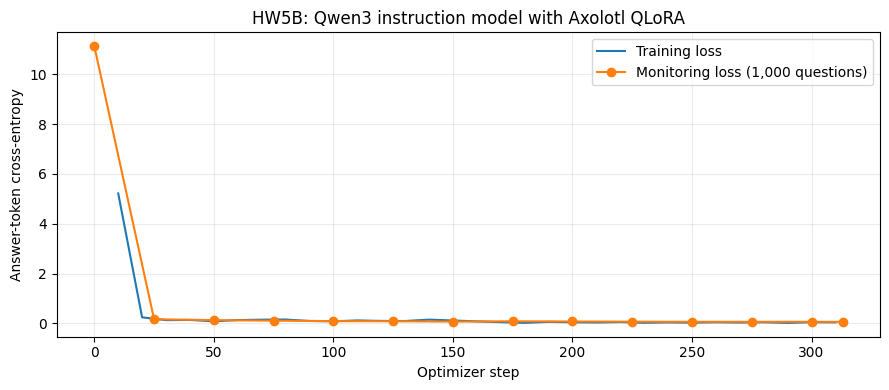

In [18]:
import matplotlib.pyplot as plt

trainer_state = json.loads((OUTPUT_DIR / "trainer_state_B.json").read_text())
history = pd.DataFrame(trainer_state["log_history"])
history.to_json(RESULTS_DIR / "training_history_B.json", orient="records", indent=2)
fig, ax = plt.subplots(figsize=(9, 4))
if "loss" in history:
    train_loss = history.dropna(subset=["loss"])
    ax.plot(train_loss["step"], train_loss["loss"], label="Training loss")
eval_loss = history.dropna(subset=["eval_loss"])
assert len(eval_loss) > 0
ax.plot(eval_loss["step"], eval_loss["eval_loss"], marker="o", label="Monitoring loss (1,000 questions)")
ax.set(xlabel="Optimizer step", ylabel="Answer-token cross-entropy",
       title="HW5B: Qwen3 instruction model with Axolotl QLoRA")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "training_loss_B.png", dpi=160)
plt.show()
assert abs(float(eval_loss["eval_loss"].min()) - measured["best_eval_loss"]) < 1e-5

## Upload the best adapter and tokenizer to Hugging Face

Axolotl writes the restored best adapter to `output_dir` after training. We
upload that adapter and its tokenizer, plus the measurement and masking
evidence. Optimizer states and the raw question dataset are not included.
The Hub repository is private; inference authenticates using the same account.

In [19]:
import shutil
import re

adapter_config = json.loads((OUTPUT_DIR / "adapter_config.json").read_text())
assert adapter_config["r"] == 128
assert adapter_config["base_model_name_or_path"] == BASE_MODEL
for filename in ["adapter_config.json", "adapter_model.safetensors"]:
    shutil.copy2(OUTPUT_DIR / filename, BEST_ADAPTER_DIR / filename)
saved_tokenizer = AutoTokenizer.from_pretrained(OUTPUT_DIR)
assert saved_tokenizer.apply_chat_template(
    train_chats[0]["messages"][:1], tokenize=False,
    add_generation_prompt=True, enable_thinking=False) == sample_generation_prompt
saved_tokenizer.save_pretrained(BEST_ADAPTER_DIR)
shutil.copy2(RESULTS_DIR / "masking_B.json", BEST_ADAPTER_DIR / "masking_B.json")
shutil.copy2(CONFIG_PATH, BEST_ADAPTER_DIR / "training_B.yaml")
summary = {
    "part": "B", "base_model": BASE_MODEL,
    "base_model_revision": BASE_MODEL_REVISION,
    "adapter_repo_id": HF_REPO_ID,
    "dataset_sha256": DATASET_SHA256, "class_names": class_names,
    "prompt_format": "hw5_single_tag_v1",
    "prompt_example_text": train_df.iloc[0]["text"],
    "prompt_example_user": make_user_prompt(train_df.iloc[0]["text"]),
    "prompt_example": sample_generation_prompt,
    "max_complete_chat_tokens": max(lengths),
    "package_versions": PACKAGE_VERSIONS,
    "run_tag": run_tag,
    **measured,
}
summary_path = RESULTS_DIR / "training_summary_B.json"
summary_path.write_text(json.dumps(summary, indent=2))
(BEST_ADAPTER_DIR / "training_summary_B.json").write_text(json.dumps(summary, indent=2))
(BEST_ADAPTER_DIR / "README.md").write_text(
    "---\nbase_model: Qwen/Qwen3-1.7B\nlibrary_name: peft\n"
    "license: apache-2.0\ntags:\n- qlora\n- text-generation\n---\n\n"
    "# HW5B single-tag adapter\n\n"
    "Qwen3-1.7B QLoRA adapter trained using Axolotl on the instructor's "
    "5,000-question Stack Exchange training split. The best checkpoint is "
    "selected using the 1,000-question monitoring split.\n\n"
    f"Training logs: {WANDB_PROJECT_URL}\n"
)
hf_api.create_repo(HF_REPO_ID, repo_type="model", private=HF_PRIVATE, exist_ok=True)
uploaded_commit = hf_api.upload_folder(
    repo_id=HF_REPO_ID, repo_type="model", folder_path=str(BEST_ADAPTER_DIR),
    commit_message="Upload HW5B best Axolotl adapter, tokenizer, and measured training summary")
summary["adapter_revision"] = uploaded_commit.oid
summary_path.write_text(json.dumps(summary, indent=2))
print("Adapter repository:", "https://huggingface.co/" + HF_REPO_ID)
print("Pinned adapter revision:", summary["adapter_revision"])
print("Summary saved:", summary_path)
display(pd.DataFrame([{
    "Training questions": summary["training_questions"],
    "Trainable parameters": summary["trainable_parameters"],
    "Training time (minutes)": summary["training_time_seconds"] / 60,
    "Peak GPU memory (GiB)": summary["peak_gpu_memory_gb"],
    "Best monitoring loss": summary["best_eval_loss"],
}]))

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   0%|          | 27.6kB /  558MB            

  ...st_adapter/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

Adapter repository: https://huggingface.co/rajatsxngh/hw5b-qwen3-instruct-tag-adapter
Pinned adapter revision: 12b978a9c5ee6344acc5ed1b302c048aced55772
Summary saved: /content/drive/MyDrive/HW5_Decoder_Tags/results/training_summary_B.json


,Training questions,Trainable parameters,Training time (minutes),Peak GPU memory (GiB),Best monitoring loss
0,5000,139460608,39.517461,2.316281,0.065417


## Next step

The best adapter is saved to Hugging Face. Part B is evaluated in **04_instruct_vllm_inference.ipynb**, run in a fresh GPU session.

Implementation references: [Axolotl conversation format](https://docs.axolotl.ai/docs/dataset-formats/conversation.html),
[Axolotl v0.17.0 chat-template strategy](https://github.com/axolotl-ai-cloud/axolotl/blob/v0.17.0/src/axolotl/prompt_strategies/chat_template.py),
and [Axolotl v0.17.0 plugin interface](https://github.com/axolotl-ai-cloud/axolotl/blob/v0.17.0/src/axolotl/integrations/base.py).

## Memory reporting correction

**Memory reporting correction:** The original 2.316281 GiB value recorded in the training summary is the final interval, because Axolotl resets its peak counters after logging. The largest saved `memory/max_allocated (GiB)` value is 11.05 GiB, rounded to two decimals. Part A reports a run-wide PyTorch peak; the two measurements should therefore be compared with caution.
